<a href="https://colab.research.google.com/github/iamshekhark/BIS-LAB/blob/main/Parallel%20Celluar/BIS_Parallel_Cellular_Algo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

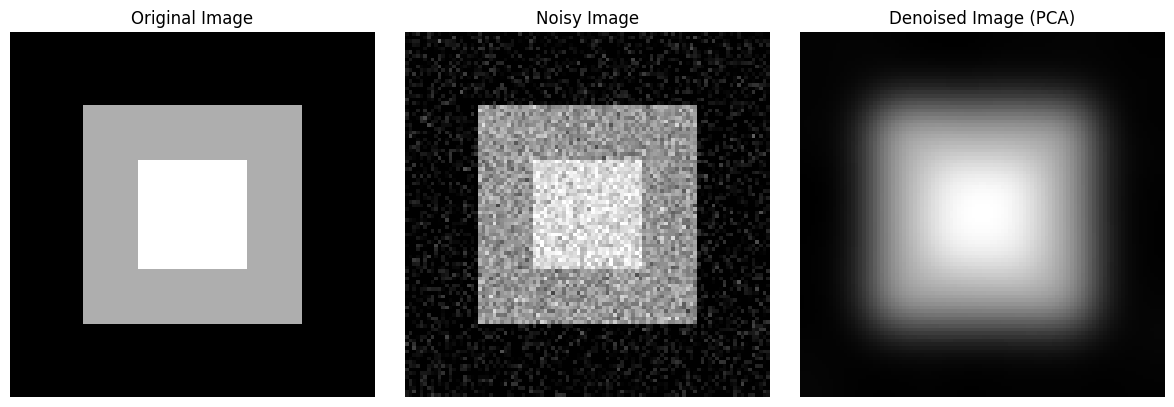

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Create a sample noisy MRI-like image
np.random.seed(42)

image = np.zeros((100, 100))
image[20:80, 20:80] = 150
image[35:65, 35:65] = 220

noise = np.random.normal(0, 25, image.shape)
noisy_image = np.clip(image + noise, 0, 255)

# Initialize PCA parameters
iterations = 100

# Parallel Cellular Algorithm
def pca_denoise(img, iterations):
    result = img.copy()

    for _ in range(iterations):

        # Pad image to handle boundary pixels
        padded = np.pad(result, 1, mode='edge')

        # Calculate average of 8 neighboring pixels
        neighbors = (
            padded[:-2, :-2] + padded[:-2, 1:-1] +
            padded[:-2, 2:] + padded[1:-1, :-2] +
            padded[1:-1, 2:] + padded[2:, :-2] +
            padded[2:, 1:-1] + padded[2:, 2:]
        ) / 8

        # Update all cells simultaneously
        result = 0.5 * result + 0.5 * neighbors

        # Keep pixel values between 0 and 255
        result = np.clip(result, 0, 255)

    return result


# Apply PCA
denoised_image = pca_denoise(noisy_image, iterations)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy_image, cmap='gray')
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(denoised_image, cmap='gray')
plt.title("Denoised Image (PCA)")
plt.axis("off")

plt.tight_layout()
plt.show()
